# NATM scenario projection plots

Recreates the two dashboard figures as static matplotlib charts:

1. **Transport demand projections** — international & domestic aviation (pkm) and international shipping (tkm), one line per Ariadne pathway.
2. **Fuel price projections** — kerosene, hydrogen, and aviation activity-weighted electricity (EUR/MWh) at the four milestone years, one line per pathway.

The data is embedded below (extracted from the per-case `aviation_scenario.csv` / `maritime_scenario.csv` files), so the notebook is self-contained — no project files are read.


In [13]:
import json, re
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ---- Academic paper style (seaborn) ----
sns.set_theme(context="paper", style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10.5,
    "axes.titlesize": 11.5,
    "axes.titleweight": "semibold",
    "axes.labelsize": 10,
    "axes.labelcolor": "#222222",
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
    "text.color": "#222222",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
    "legend.fontsize": 8.5,
    "legend.frameon": False,
    "grid.color": "#d9d9d9",
    "grid.linewidth": 0.6,
    "axes.grid.which": "major",
})
sns.despine()

# One consistent colour per Ariadne pathway, from the Okabe-Ito colourblind-safe
# qualitative palette (validated: all CVD modes >= ~7.6 OKLab dE, normal >= 15).
PATHWAY_ORDER = ["aktuellepolitiken", "fokusstrom", "fokusH2",
                 "technologiemix", "hohenachfrage", "niedrigenachfrage"]
PATHWAY_LABEL = {
    "aktuellepolitiken": "ExPol",
    "fokusstrom": "Elec",
    "fokusH2": "H₂",
    "technologiemix": "Mix",
    "hohenachfrage": "HighDem",
    "niedrigenachfrage": "LowDem",
}
COLORS = {
    "aktuellepolitiken": "#0072B2",   # blue
    "fokusstrom":        "#E69F00",   # orange
    "fokusH2":           "#009E73",   # bluish green
    "technologiemix":    "#CC79A7",   # reddish purple
    "hohenachfrage":     "#D55E00",   # vermillion
    "niedrigenachfrage": "#56B4E9",   # sky blue
}


<Figure size 832x624 with 0 Axes>

## Data (embedded)

In [14]:
def _js_to_json(s):
    s = '[' + s + ']'
    s = re.sub(r'([{,])\s*([A-Za-z_]\w*)\s*:', r'\1"\2":', s)
    return s.replace("'", '"')

DEMAND_RAW = r'''{series:'intl',panel:'International aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2025,v:200.0018,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:195.3572,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:194.347,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:191.67,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:193.3258,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2050,v:193.0225,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2025,v:202.8452,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:190.3615,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:172.7145,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:155.6097,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:150.1633,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2050,v:157.8021,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2025,v:201.85,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2030,v:192.622,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2035,v:169.5142,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2040,v:149.2466,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2045,v:142.24,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2050,v:145.1224,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2025,v:202.6688,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2030,v:192.4463,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2035,v:176.9608,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2040,v:159.8539,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2045,v:153.3259,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2050,v:161.0819,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2025,v:200.873,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:189.6586,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:169.8437,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:151.7742,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:144.6291,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2050,v:147.9022,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2025,v:191.1842,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:180.1212,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:154.5391,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:134.7325,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:122.3145,unit:'bn pkm'},{series:'intl',panel:'International aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2050,v:119.9678,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2025,v:7.71587,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:8.238908,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:8.465852,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:7.601238,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:6.999996,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2050,v:6.902289,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2025,v:7.345665,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:6.30344,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:4.36277,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:2.795592,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:2.284706,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusstrom',label:'FokusStrom',year:2050,v:2.305169,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2025,v:7.39483,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2030,v:6.361581,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2035,v:4.163284,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2040,v:2.436318,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2045,v:1.847063,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'fokusH2',label:'FokusH2',year:2050,v:1.765963,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2025,v:7.428984,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2030,v:6.673811,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2035,v:4.842491,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2040,v:3.168151,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2045,v:2.58683,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'technologiemix',label:'Technologiemix',year:2050,v:2.450347,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2025,v:7.077492,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:5.786817,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:3.911551,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:2.416489,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:1.9505,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2050,v:2.116354,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2025,v:8.030147,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:7.72641,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:6.179655,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:4.331726,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:3.683577,unit:'bn pkm'},{series:'dom',panel:'Domestic aviation, pkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2050,v:2.989801,unit:'bn pkm'},{series:'ship',panel:'International shipping, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2025,v:1132.589,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:1085.835,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:1083.662,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:1072.627,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:1088.106,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2050,v:1093.808,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2025,v:1152.703,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:1050.792,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:941.419,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:835.69,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:802.8498,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2050,v:846.5119,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusH2',label:'FokusH2',year:2025,v:1147.746,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusH2',label:'FokusH2',year:2030,v:1069.873,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusH2',label:'FokusH2',year:2035,v:925.2986,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusH2',label:'FokusH2',year:2040,v:800.4855,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusH2',label:'FokusH2',year:2045,v:754.0194,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'fokusH2',label:'FokusH2',year:2050,v:772.8511,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'technologiemix',label:'Technologiemix',year:2025,v:1150.407,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'technologiemix',label:'Technologiemix',year:2030,v:1066.186,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'technologiemix',label:'Technologiemix',year:2035,v:970.5334,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'technologiemix',label:'Technologiemix',year:2040,v:865.7197,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'technologiemix',label:'Technologiemix',year:2045,v:825.5345,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'technologiemix',label:'Technologiemix',year:2050,v:871.3598,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2025,v:1124.674,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:1030.89,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:896.1981,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:788.8556,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:747.0533,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2050,v:760.8934,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2025,v:1113.531,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:1078.43,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:918.9942,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:811.096,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:760.4907,unit:'bn tkm'},{series:'ship',panel:'International shipping, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2050,v:778.4789,unit:'bn tkm'}'''

PRICE_RAW = r'''{series:'kero',panel:'Kerosene',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:42.2},{series:'kero',panel:'Kerosene',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:85.7},{series:'kero',panel:'Kerosene',pathway:'fokusH2',label:'FokusH2',year:2030,v:86.9},{series:'kero',panel:'Kerosene',pathway:'technologiemix',label:'Technologiemix',year:2030,v:86.4},{series:'kero',panel:'Kerosene',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:89.0},{series:'kero',panel:'Kerosene',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:79.6},{series:'kero',panel:'Kerosene',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:41.5},{series:'kero',panel:'Kerosene',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:174.2},{series:'kero',panel:'Kerosene',pathway:'fokusH2',label:'FokusH2',year:2035,v:176.2},{series:'kero',panel:'Kerosene',pathway:'technologiemix',label:'Technologiemix',year:2035,v:175.4},{series:'kero',panel:'Kerosene',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:178.2},{series:'kero',panel:'Kerosene',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:167.1},{series:'kero',panel:'Kerosene',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:40.6},{series:'kero',panel:'Kerosene',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:184.1},{series:'kero',panel:'Kerosene',pathway:'fokusH2',label:'FokusH2',year:2040,v:188.1},{series:'kero',panel:'Kerosene',pathway:'technologiemix',label:'Technologiemix',year:2040,v:187.6},{series:'kero',panel:'Kerosene',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:192.8},{series:'kero',panel:'Kerosene',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:180.5},{series:'kero',panel:'Kerosene',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:40.4},{series:'kero',panel:'Kerosene',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:144.9},{series:'kero',panel:'Kerosene',pathway:'fokusH2',label:'FokusH2',year:2045,v:139.3},{series:'kero',panel:'Kerosene',pathway:'technologiemix',label:'Technologiemix',year:2045,v:147.8},{series:'kero',panel:'Kerosene',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:152.3},{series:'kero',panel:'Kerosene',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:132.4},{series:'h2',panel:'Hydrogen',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:59.5},{series:'h2',panel:'Hydrogen',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:88.2},{series:'h2',panel:'Hydrogen',pathway:'fokusH2',label:'FokusH2',year:2030,v:89.5},{series:'h2',panel:'Hydrogen',pathway:'technologiemix',label:'Technologiemix',year:2030,v:88.9},{series:'h2',panel:'Hydrogen',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:91.6},{series:'h2',panel:'Hydrogen',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:82.1},{series:'h2',panel:'Hydrogen',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:44.7},{series:'h2',panel:'Hydrogen',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:116.4},{series:'h2',panel:'Hydrogen',pathway:'fokusH2',label:'FokusH2',year:2035,v:118.3},{series:'h2',panel:'Hydrogen',pathway:'technologiemix',label:'Technologiemix',year:2035,v:117.5},{series:'h2',panel:'Hydrogen',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:118.3},{series:'h2',panel:'Hydrogen',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:116.1},{series:'h2',panel:'Hydrogen',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:44.6},{series:'h2',panel:'Hydrogen',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:112.9},{series:'h2',panel:'Hydrogen',pathway:'fokusH2',label:'FokusH2',year:2040,v:115.0},{series:'h2',panel:'Hydrogen',pathway:'technologiemix',label:'Technologiemix',year:2040,v:113.5},{series:'h2',panel:'Hydrogen',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:114.8},{series:'h2',panel:'Hydrogen',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:111.2},{series:'h2',panel:'Hydrogen',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:44.8},{series:'h2',panel:'Hydrogen',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:98.4},{series:'h2',panel:'Hydrogen',pathway:'fokusH2',label:'FokusH2',year:2045,v:94.4},{series:'h2',panel:'Hydrogen',pathway:'technologiemix',label:'Technologiemix',year:2045,v:99.7},{series:'h2',panel:'Hydrogen',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:101.4},{series:'h2',panel:'Hydrogen',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:94.3},{series:'el',panel:'Electricity, aviation-weighted',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:10.7},{series:'el',panel:'Electricity, aviation-weighted',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:43.9},{series:'el',panel:'Electricity, aviation-weighted',pathway:'fokusH2',label:'FokusH2',year:2030,v:43.2},{series:'el',panel:'Electricity, aviation-weighted',pathway:'technologiemix',label:'Technologiemix',year:2030,v:44.4},{series:'el',panel:'Electricity, aviation-weighted',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:43.2},{series:'el',panel:'Electricity, aviation-weighted',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:44.3},{series:'el',panel:'Electricity, aviation-weighted',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:5.8},{series:'el',panel:'Electricity, aviation-weighted',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:36.2},{series:'el',panel:'Electricity, aviation-weighted',pathway:'fokusH2',label:'FokusH2',year:2035,v:390.0},{series:'el',panel:'Electricity, aviation-weighted',pathway:'technologiemix',label:'Technologiemix',year:2035,v:45.1},{series:'el',panel:'Electricity, aviation-weighted',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:38.8},{series:'el',panel:'Electricity, aviation-weighted',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:31.6},{series:'el',panel:'Electricity, aviation-weighted',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:16.2},{series:'el',panel:'Electricity, aviation-weighted',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:41.5},{series:'el',panel:'Electricity, aviation-weighted',pathway:'fokusH2',label:'FokusH2',year:2040,v:767.9},{series:'el',panel:'Electricity, aviation-weighted',pathway:'technologiemix',label:'Technologiemix',year:2040,v:29.4},{series:'el',panel:'Electricity, aviation-weighted',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:38.4},{series:'el',panel:'Electricity, aviation-weighted',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:27.0},{series:'el',panel:'Electricity, aviation-weighted',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:14.7},{series:'el',panel:'Electricity, aviation-weighted',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:36.6},{series:'el',panel:'Electricity, aviation-weighted',pathway:'fokusH2',label:'FokusH2',year:2045,v:23.2},{series:'el',panel:'Electricity, aviation-weighted',pathway:'technologiemix',label:'Technologiemix',year:2045,v:32.0},{series:'el',panel:'Electricity, aviation-weighted',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:25.5},{series:'el',panel:'Electricity, aviation-weighted',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:29.9}'''

demand = json.loads(_js_to_json(DEMAND_RAW))
price  = json.loads(_js_to_json(PRICE_RAW))
print(f'{len(demand)} demand rows, {len(price)} price rows')


108 demand rows, 72 price rows


## 1 · Transport demand projections

Each panel is a transport segment; each line is a pathway. Aviation panels are in billion passenger-kilometres, shipping in billion tonne-kilometres.

Note: the aviation passenger series is anchored to **seat-kilometre capacity** by construction, though it is carried in the scenario files under a `passenger_km_demand` label.

findfont: Failed to find font weight semibold, now using 700.


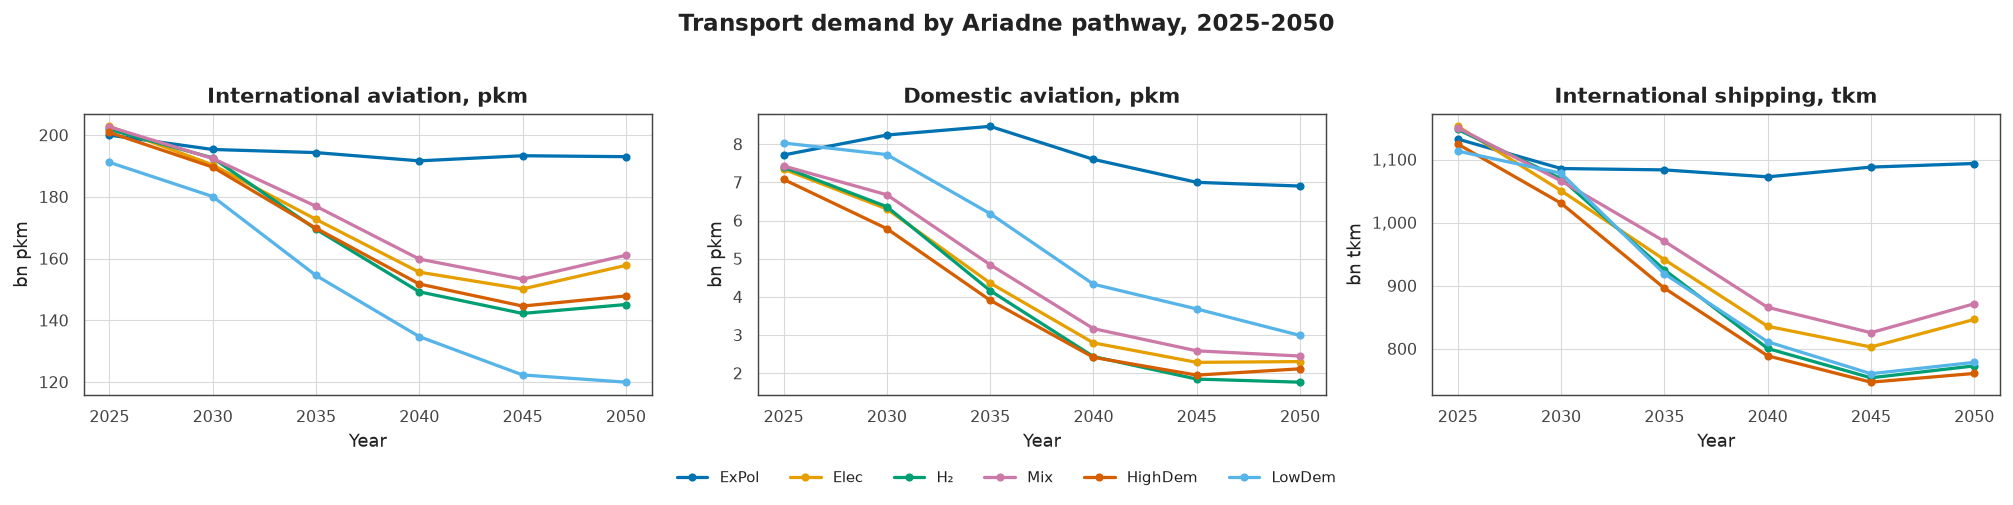

In [15]:
def plot_panels(rows, panels, ncols, ylabel_fmt, suptitle, fname=None):
    nrows = -(-len(panels) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 3.6*nrows), squeeze=False)
    axes = axes.ravel()
    for ax, panel in zip(axes, panels):
        for pw in PATHWAY_ORDER:
            pts = sorted([r for r in rows if r["panel"] == panel and r["pathway"] == pw],
                         key=lambda r: r["year"])
            if not pts:
                continue
            ax.plot([p["year"] for p in pts], [p["v"] for p in pts],
                    marker="o", ms=3.5, lw=1.8, color=COLORS[pw],
                    label=PATHWAY_LABEL[pw])
        ax.set_title(panel)
        ax.set_xlabel("Year")
        unit = next((r.get("unit","") for r in rows if r["panel"] == panel), "")
        ax.set_ylabel(unit)
        ax.yaxis.set_major_formatter(FuncFormatter(ylabel_fmt))
    for ax in axes[len(panels):]:
        ax.set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, ncol=len(PATHWAY_ORDER), loc="lower center",
               frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    if fname:
        fig.savefig(fname, bbox_inches="tight", dpi=150)
        fig.savefig(re.sub(r"\.png$", ".pdf", fname), bbox_inches="tight")
    plt.show()

demand_panels = ["International aviation, pkm", "Domestic aviation, pkm", "International shipping, tkm"]
plot_panels(demand, demand_panels, ncols=3,
            ylabel_fmt=lambda v, _: f"{v:,.0f}",
            suptitle="Transport demand by Ariadne pathway, 2025-2050",
            fname="scenario_demand_projections.png")


## 2 · Fuel price projections

Milestone-year fuel prices (EUR/MWh) by pathway. The electricity panel is the aviation activity-weighted day-ahead price; its FokusH2 spikes in 2035 (390) and 2040 (768) reflect the embedded consumption-weighted peaks.

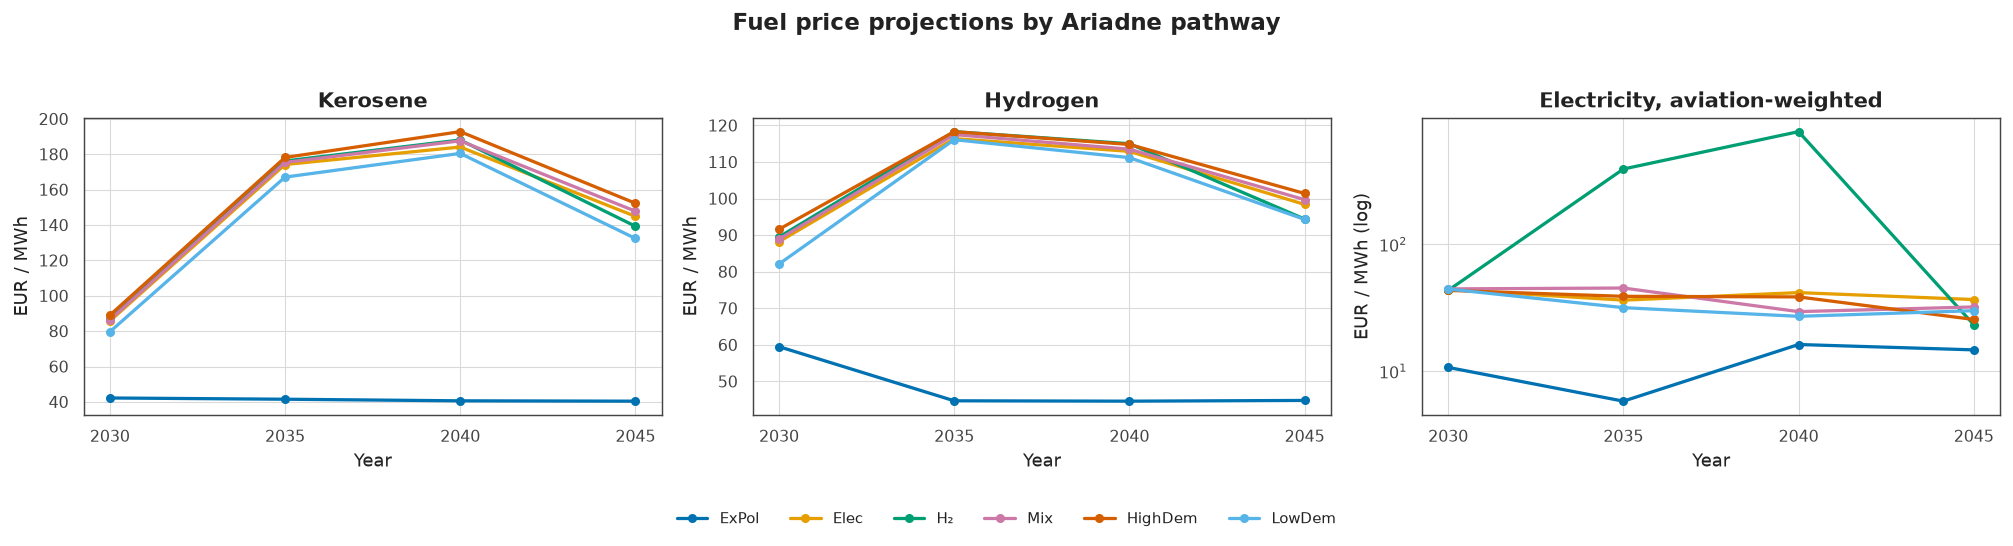

In [16]:
price_panels = ["Kerosene", "Hydrogen", "Electricity, aviation-weighted"]

def plot_prices(rows, panels, logy_panels=()):
    fig, axes = plt.subplots(1, len(panels), figsize=(5.2*len(panels), 3.8), squeeze=False)
    axes = axes.ravel()
    for ax, panel in zip(axes, panels):
        for pw in PATHWAY_ORDER:
            pts = sorted([r for r in rows if r["panel"] == panel and r["pathway"] == pw],
                         key=lambda r: r["year"])
            if not pts:
                continue
            ax.plot([p["year"] for p in pts], [p["v"] for p in pts],
                    marker="o", ms=4, lw=1.8, color=COLORS[pw], label=PATHWAY_LABEL[pw])
        ax.set_title(panel)
        ax.set_xlabel("Year")
        ax.set_ylabel("EUR / MWh")
        ax.set_xticks([2030, 2035, 2040, 2045])
        if panel in logy_panels:
            ax.set_yscale("log")
            ax.set_ylabel("EUR / MWh (log)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, ncol=len(PATHWAY_ORDER), loc="lower center",
               frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.suptitle("Fuel price projections by Ariadne pathway", fontsize=13, fontweight="bold", y=1.03)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig("scenario_price_projections.png", bbox_inches="tight", dpi=150)
    fig.savefig("scenario_price_projections.pdf", bbox_inches="tight")
    plt.show()

# Electricity panel uses a log y-axis so the FokusH2 spikes don't flatten the others.
plot_prices(price, price_panels, logy_panels=("Electricity, aviation-weighted",))


## 3 · Maritime cargo fuel price projections

Primary-energy fuel prices for the maritime cargo fleet (EUR/MWh) at the four milestone years, one line per Ariadne pathway. Panels: marine diesel, methanol, ammonia, hydrogen, LNG, and the maritime activity-weighted electricity price.

Prices are the aggregate (fleet-level) series; ammonia is supplied as a single common trajectory across pathways, so it shows one line. The maritime electricity panel uses a log y-axis — FokusH2 spikes to ~406 (2035) and ~130 (2040) EUR/MWh while the others stay near 30-60.

In [17]:
MARITIME_PRICE_RAW = r'''{series:'marine_diesel',panel:'Marine diesel',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:65.66},{series:'marine_diesel',panel:'Marine diesel',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:56.91},{series:'marine_diesel',panel:'Marine diesel',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:43.96},{series:'marine_diesel',panel:'Marine diesel',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:44.59},{series:'lng',panel:'LNG',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:24.01},{series:'lng',panel:'LNG',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:23.85},{series:'lng',panel:'LNG',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:23.67},{series:'lng',panel:'LNG',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:23.9},{series:'methanol',panel:'Methanol',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:89.46},{series:'methanol',panel:'Methanol',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:72.66},{series:'methanol',panel:'Methanol',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:72.81},{series:'methanol',panel:'Methanol',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:73.77},{series:'hydrogen',panel:'Hydrogen',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:59.48},{series:'hydrogen',panel:'Hydrogen',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:44.67},{series:'hydrogen',panel:'Hydrogen',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:44.57},{series:'hydrogen',panel:'Hydrogen',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:44.79},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:24.2},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:18.83},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:29.46},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:30.31},{series:'marine_diesel',panel:'Marine diesel',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:85.73},{series:'marine_diesel',panel:'Marine diesel',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:174.2},{series:'marine_diesel',panel:'Marine diesel',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:184.1},{series:'marine_diesel',panel:'Marine diesel',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:146.6},{series:'lng',panel:'LNG',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:24.61},{series:'lng',panel:'LNG',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:27.42},{series:'lng',panel:'LNG',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:27.94},{series:'lng',panel:'LNG',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:27.01},{series:'methanol',panel:'Methanol',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:130.8},{series:'methanol',panel:'Methanol',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:163.6},{series:'methanol',panel:'Methanol',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:170.9},{series:'methanol',panel:'Methanol',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:148.6},{series:'hydrogen',panel:'Hydrogen',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:88.23},{series:'hydrogen',panel:'Hydrogen',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:116.4},{series:'hydrogen',panel:'Hydrogen',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:112.9},{series:'hydrogen',panel:'Hydrogen',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:98.43},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:60.44},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:44.11},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:38.25},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:35.3},{series:'marine_diesel',panel:'Marine diesel',pathway:'fokusH2',label:'FokusH2',year:2030,v:86.86},{series:'marine_diesel',panel:'Marine diesel',pathway:'fokusH2',label:'FokusH2',year:2035,v:176.2},{series:'marine_diesel',panel:'Marine diesel',pathway:'fokusH2',label:'FokusH2',year:2040,v:188.1},{series:'marine_diesel',panel:'Marine diesel',pathway:'fokusH2',label:'FokusH2',year:2045,v:139.3},{series:'lng',panel:'LNG',pathway:'fokusH2',label:'FokusH2',year:2030,v:24.65},{series:'lng',panel:'LNG',pathway:'fokusH2',label:'FokusH2',year:2035,v:27.48},{series:'lng',panel:'LNG',pathway:'fokusH2',label:'FokusH2',year:2040,v:28.06},{series:'lng',panel:'LNG',pathway:'fokusH2',label:'FokusH2',year:2045,v:26.79},{series:'methanol',panel:'Methanol',pathway:'fokusH2',label:'FokusH2',year:2030,v:132.2},{series:'methanol',panel:'Methanol',pathway:'fokusH2',label:'FokusH2',year:2035,v:165.8},{series:'methanol',panel:'Methanol',pathway:'fokusH2',label:'FokusH2',year:2040,v:174.5},{series:'methanol',panel:'Methanol',pathway:'fokusH2',label:'FokusH2',year:2045,v:141.8},{series:'hydrogen',panel:'Hydrogen',pathway:'fokusH2',label:'FokusH2',year:2030,v:89.46},{series:'hydrogen',panel:'Hydrogen',pathway:'fokusH2',label:'FokusH2',year:2035,v:118.3},{series:'hydrogen',panel:'Hydrogen',pathway:'fokusH2',label:'FokusH2',year:2040,v:115},{series:'hydrogen',panel:'Hydrogen',pathway:'fokusH2',label:'FokusH2',year:2045,v:94.4},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'fokusH2',label:'FokusH2',year:2030,v:58.61},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'fokusH2',label:'FokusH2',year:2035,v:406.3},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'fokusH2',label:'FokusH2',year:2040,v:129.9},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'fokusH2',label:'FokusH2',year:2045,v:27.94},{series:'marine_diesel',panel:'Marine diesel',pathway:'technologiemix',label:'Technologiemix',year:2030,v:86.37},{series:'marine_diesel',panel:'Marine diesel',pathway:'technologiemix',label:'Technologiemix',year:2035,v:175.4},{series:'marine_diesel',panel:'Marine diesel',pathway:'technologiemix',label:'Technologiemix',year:2040,v:187.6},{series:'marine_diesel',panel:'Marine diesel',pathway:'technologiemix',label:'Technologiemix',year:2045,v:147.9},{series:'lng',panel:'LNG',pathway:'technologiemix',label:'Technologiemix',year:2030,v:24.63},{series:'lng',panel:'LNG',pathway:'technologiemix',label:'Technologiemix',year:2035,v:27.46},{series:'lng',panel:'LNG',pathway:'technologiemix',label:'Technologiemix',year:2040,v:28.05},{series:'lng',panel:'LNG',pathway:'technologiemix',label:'Technologiemix',year:2045,v:27.05},{series:'methanol',panel:'Methanol',pathway:'technologiemix',label:'Technologiemix',year:2030,v:131.6},{series:'methanol',panel:'Methanol',pathway:'technologiemix',label:'Technologiemix',year:2035,v:164.9},{series:'methanol',panel:'Methanol',pathway:'technologiemix',label:'Technologiemix',year:2040,v:174.2},{series:'methanol',panel:'Methanol',pathway:'technologiemix',label:'Technologiemix',year:2045,v:149.9},{series:'hydrogen',panel:'Hydrogen',pathway:'technologiemix',label:'Technologiemix',year:2030,v:88.93},{series:'hydrogen',panel:'Hydrogen',pathway:'technologiemix',label:'Technologiemix',year:2035,v:117.5},{series:'hydrogen',panel:'Hydrogen',pathway:'technologiemix',label:'Technologiemix',year:2040,v:113.5},{series:'hydrogen',panel:'Hydrogen',pathway:'technologiemix',label:'Technologiemix',year:2045,v:99.67},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'technologiemix',label:'Technologiemix',year:2030,v:59.56},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'technologiemix',label:'Technologiemix',year:2035,v:43.38},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'technologiemix',label:'Technologiemix',year:2040,v:36.51},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'technologiemix',label:'Technologiemix',year:2045,v:33.59},{series:'marine_diesel',panel:'Marine diesel',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:89},{series:'marine_diesel',panel:'Marine diesel',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:178.2},{series:'marine_diesel',panel:'Marine diesel',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:192.8},{series:'marine_diesel',panel:'Marine diesel',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:152.3},{series:'lng',panel:'LNG',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:24.71},{series:'lng',panel:'LNG',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:27.54},{series:'lng',panel:'LNG',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:28.21},{series:'lng',panel:'LNG',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:27.19},{series:'methanol',panel:'Methanol',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:135.1},{series:'methanol',panel:'Methanol',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:166.6},{series:'methanol',panel:'Methanol',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:179},{series:'methanol',panel:'Methanol',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:153.1},{series:'hydrogen',panel:'Hydrogen',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:91.58},{series:'hydrogen',panel:'Hydrogen',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:118.3},{series:'hydrogen',panel:'Hydrogen',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:114.8},{series:'hydrogen',panel:'Hydrogen',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:101.4},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:59.68},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:43.42},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:36.76},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:34.46},{series:'marine_diesel',panel:'Marine diesel',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:79.57},{series:'marine_diesel',panel:'Marine diesel',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:167.1},{series:'marine_diesel',panel:'Marine diesel',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:180.5},{series:'marine_diesel',panel:'Marine diesel',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:132.4},{series:'lng',panel:'LNG',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:24.43},{series:'lng',panel:'LNG',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:27.21},{series:'lng',panel:'LNG',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:27.83},{series:'lng',panel:'LNG',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:26.58},{series:'methanol',panel:'Methanol',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:123},{series:'methanol',panel:'Methanol',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:161.6},{series:'methanol',panel:'Methanol',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:168},{series:'methanol',panel:'Methanol',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:136.3},{series:'hydrogen',panel:'Hydrogen',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:82.07},{series:'hydrogen',panel:'Hydrogen',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:116.1},{series:'hydrogen',panel:'Hydrogen',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:111.2},{series:'hydrogen',panel:'Hydrogen',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:94.27},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:58.74},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:42.59},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:36.46},{series:'electricity',panel:'Electricity, maritime-weighted',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:32.12},{series:'ammonia',panel:'Ammonia',pathway:'common',label:'All pathways',year:2030,v:151.4},{series:'ammonia',panel:'Ammonia',pathway:'common',label:'All pathways',year:2035,v:144.6},{series:'ammonia',panel:'Ammonia',pathway:'common',label:'All pathways',year:2040,v:144.6},{series:'ammonia',panel:'Ammonia',pathway:'common',label:'All pathways',year:2045,v:144.6}'''

maritime_price = json.loads(_js_to_json(MARITIME_PRICE_RAW))
print(f'{len(maritime_price)} maritime price rows')


124 maritime price rows


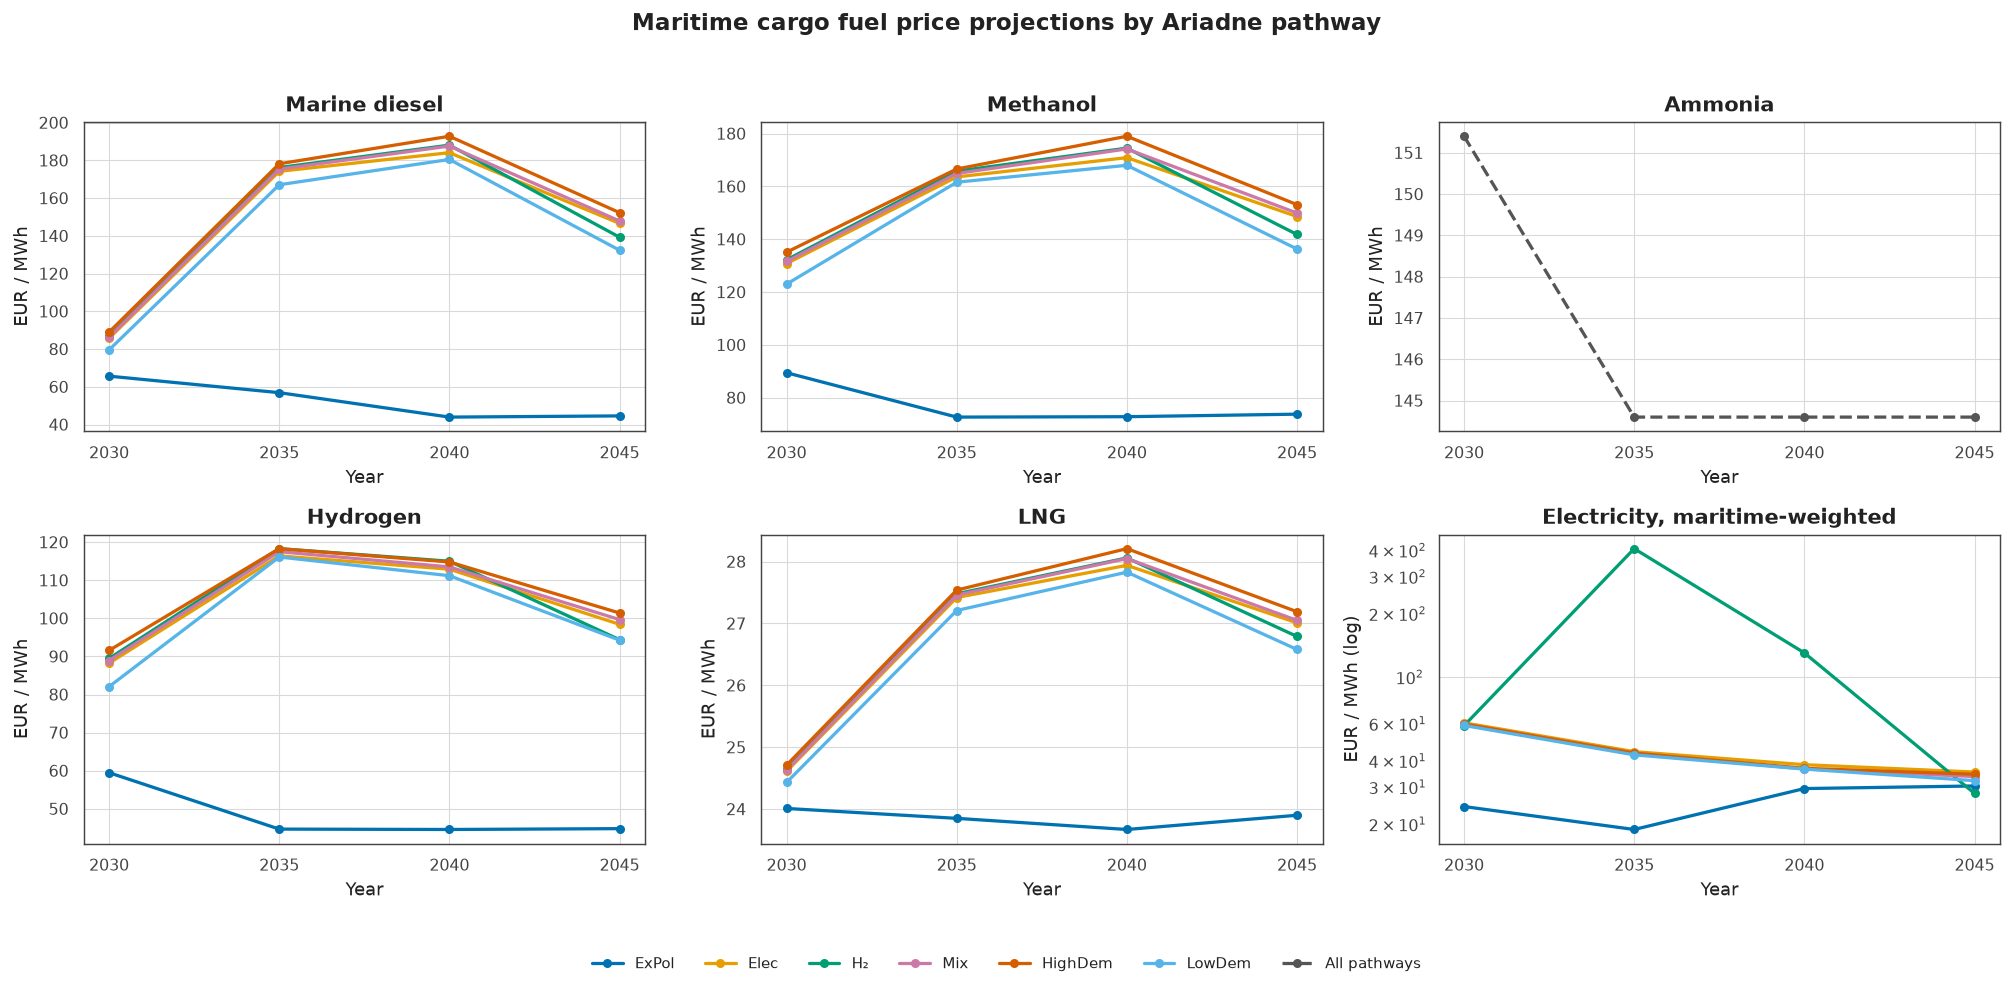

In [18]:
def plot_maritime_prices(rows, panels, logy_panels=(), ncols=3):
    # pathways that actually appear, in canonical order, plus a 'common' line if present
    order = PATHWAY_ORDER + (["common"] if any(r["pathway"] == "common" for r in rows) else [])
    colors = dict(COLORS); colors["common"] = "#555555"
    labels = dict(PATHWAY_LABEL); labels["common"] = "All pathways"
    nrows = -(-len(panels) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 3.6*nrows), squeeze=False)
    axes = axes.ravel()
    for ax, panel in zip(axes, panels):
        for pw in order:
            pts = sorted([r for r in rows if r["panel"] == panel and r["pathway"] == pw],
                         key=lambda r: r["year"])
            if not pts:
                continue
            ax.plot([p["year"] for p in pts], [p["v"] for p in pts],
                    marker="o", ms=4, lw=1.8,
                    color=colors[pw], label=labels[pw],
                    linestyle="--" if pw == "common" else "-")
        ax.set_title(panel)
        ax.set_xlabel("Year"); ax.set_ylabel("EUR / MWh")
        ax.set_xticks([2030, 2035, 2040, 2045])
        if panel in logy_panels:
            ax.set_yscale("log"); ax.set_ylabel("EUR / MWh (log)")
    for ax in axes[len(panels):]:
        ax.set_visible(False)
    # build a combined legend
    seen = {}
    for ax in axes[:len(panels)]:
        for h, l in zip(*ax.get_legend_handles_labels()):
            seen.setdefault(l, h)
    fig.legend(seen.values(), seen.keys(), ncol=min(7, len(seen)), loc="lower center",
               frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Maritime cargo fuel price projections by Ariadne pathway",
                 fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig("scenario_maritime_price_projections.png", bbox_inches="tight", dpi=150)
    fig.savefig("scenario_maritime_price_projections.pdf", bbox_inches="tight")
    plt.show()

maritime_panels = ["Marine diesel", "Methanol", "Ammonia",
                   "Hydrogen", "LNG", "Electricity, maritime-weighted"]
plot_maritime_prices(maritime_price, maritime_panels,
                     logy_panels=("Electricity, maritime-weighted",))


## 4 · Freight (cargo) demand — tonne-kilometres

Cargo transport demand measured as **freight tonne-kilometres** (`freight_tonne_km_demand`, billion tkm/year), which is the quantity the fleet is sized against — distinct from the aggregate "shipping tkm" activity line in Figure 1.

- **Air cargo** — segments *long* + *medium* summed to a total; one common trajectory across all pathways (shown as a single dashed line), rising ~25 % to 2035 then held flat.
- **Maritime deep-sea** and **Maritime regional** — pathway-specific, interpolated year by year between the Ariadne milestones.

Note the scale difference: air cargo is ~8 bn tkm, maritime deep-sea ~330 bn tkm, maritime regional ~64 bn tkm — so each sits in its own panel.

In [19]:
CARGO_DEMAND_RAW = r'''{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2025,v:8.3886,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2026,v:8.3886,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2027,v:8.3886,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2028,v:8.3886,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2029,v:8.3886,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2030,v:9.5985,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2031,v:9.5985,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2032,v:9.5985,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2033,v:9.5985,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2034,v:9.5985,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2035,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2036,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2037,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2038,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2039,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2040,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2041,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2042,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2043,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2044,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2045,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2046,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2047,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2048,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2049,v:10.9841,unit:'bn tkm'},{series:'air',panel:'Air cargo freight, tkm',pathway:'common',label:'All pathways',year:2050,v:10.9841,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2025,v:332.4991,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2026,v:329.7539,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2027,v:327.0088,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2028,v:324.2636,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2029,v:321.5184,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:318.7733,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2031,v:318.6457,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2032,v:318.5181,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2033,v:318.3905,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2034,v:318.2629,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:318.1354,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2036,v:317.4874,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2037,v:316.8395,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2038,v:316.1916,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2039,v:315.5437,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:314.8958,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2041,v:315.8046,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2042,v:316.7135,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2043,v:317.6223,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2044,v:318.5312,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:319.44,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2046,v:319.7748,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2047,v:320.1096,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2048,v:320.4444,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2049,v:320.7792,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2050,v:321.114,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2025,v:332.4991,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2026,v:326.6198,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2027,v:320.7405,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2028,v:314.8612,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2029,v:308.982,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:303.1027,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2031,v:296.7929,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2032,v:290.4831,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2033,v:284.1734,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2034,v:277.8636,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:271.5539,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2036,v:265.4543,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2037,v:259.3548,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2038,v:253.2552,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2039,v:247.1557,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:241.0561,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2041,v:239.1616,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2042,v:237.267,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2043,v:235.3725,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2044,v:233.4779,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:231.5833,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2046,v:234.1022,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2047,v:236.6211,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2048,v:239.14,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2049,v:241.6589,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2050,v:244.1777,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2025,v:332.4991,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2026,v:327.9871,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2027,v:323.4752,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2028,v:318.9633,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2029,v:314.4514,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2030,v:309.9395,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2031,v:301.5629,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2032,v:293.1863,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2033,v:284.8098,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2034,v:276.4332,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2035,v:268.0566,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2036,v:260.825,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2037,v:253.5934,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2038,v:246.3618,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2039,v:239.1302,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2040,v:231.8986,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2041,v:229.2064,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2042,v:226.5141,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2043,v:223.8219,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2044,v:221.1297,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2045,v:218.4375,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2046,v:219.5286,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2047,v:220.6197,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2048,v:221.7108,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2049,v:222.8019,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2050,v:223.893,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2025,v:332.4991,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2026,v:327.6306,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2027,v:322.7622,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2028,v:317.8938,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2029,v:313.0253,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2030,v:308.1569,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2031,v:302.6277,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2032,v:297.0984,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2033,v:291.5692,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2034,v:286.0399,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2035,v:280.5107,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2036,v:274.4519,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2037,v:268.3931,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2038,v:262.3343,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2039,v:256.2755,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2040,v:250.2167,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2041,v:247.8937,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2042,v:245.5708,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2043,v:243.2479,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2044,v:240.925,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2045,v:238.602,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2046,v:241.251,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2047,v:243.8999,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2048,v:246.5489,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2049,v:249.1978,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2050,v:251.8468,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2025,v:332.4991,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2026,v:326.9538,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2027,v:321.4085,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2028,v:315.8633,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2029,v:310.318,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:304.7727,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2031,v:296.8087,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2032,v:288.8446,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2033,v:280.8805,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2034,v:272.9164,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:264.9524,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2036,v:258.6054,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2037,v:252.2585,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2038,v:245.9115,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2039,v:239.5645,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:233.2176,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2041,v:230.7459,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2042,v:228.2742,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2043,v:225.8025,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2044,v:223.3308,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:220.8591,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2046,v:221.6775,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2047,v:222.4958,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2048,v:223.3142,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2049,v:224.1325,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2050,v:224.9508,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2025,v:332.4991,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2026,v:330.4028,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2027,v:328.3066,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2028,v:326.2104,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2029,v:324.1142,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:322.018,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2031,v:312.4965,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2032,v:302.975,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2033,v:293.4535,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2034,v:283.9321,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:274.4106,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2036,v:267.9669,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2037,v:261.5233,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2038,v:255.0796,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2039,v:248.636,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:242.1923,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2041,v:239.1702,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2042,v:236.1481,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2043,v:233.1259,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2044,v:230.1038,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:227.0816,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2046,v:228.1559,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2047,v:229.2301,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2048,v:230.3044,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2049,v:231.3786,unit:'bn tkm'},{series:'deepsea',panel:'Maritime deep-sea freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2050,v:232.4529,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2025,v:64.3239,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2026,v:63.7929,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2027,v:63.2618,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2028,v:62.7307,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2029,v:62.1997,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2030,v:61.6686,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2031,v:61.6439,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2032,v:61.6192,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2033,v:61.5946,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2034,v:61.5699,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2035,v:61.5452,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2036,v:61.4198,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2037,v:61.2945,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2038,v:61.1692,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2039,v:61.0438,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2040,v:60.9185,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2041,v:61.0943,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2042,v:61.2701,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2043,v:61.4459,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2044,v:61.6218,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2045,v:61.7976,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2046,v:61.8623,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2047,v:61.9271,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2048,v:61.9919,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2049,v:62.0566,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'aktuellepolitiken',label:'AktuellePolitiken',year:2050,v:62.1214,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2025,v:64.3239,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2026,v:63.1866,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2027,v:62.0492,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2028,v:60.9118,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2029,v:59.7744,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2030,v:58.637,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2031,v:57.4164,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2032,v:56.1957,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2033,v:54.975,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2034,v:53.7544,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2035,v:52.5337,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2036,v:51.3537,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2037,v:50.1737,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2038,v:48.9937,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2039,v:47.8137,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2040,v:46.6338,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2041,v:46.2672,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2042,v:45.9007,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2043,v:45.5342,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2044,v:45.1677,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2045,v:44.8012,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2046,v:45.2885,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2047,v:45.7758,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2048,v:46.2631,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2049,v:46.7504,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusstrom',label:'FokusStrom',year:2050,v:47.2376,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2025,v:64.3239,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2026,v:63.4511,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2027,v:62.5782,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2028,v:61.7054,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2029,v:60.8325,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2030,v:59.9596,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2031,v:58.3391,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2032,v:56.7186,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2033,v:55.0982,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2034,v:53.4777,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2035,v:51.8572,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2036,v:50.4582,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2037,v:49.0592,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2038,v:47.6602,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2039,v:46.2612,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2040,v:44.8622,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2041,v:44.3413,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2042,v:43.8205,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2043,v:43.2997,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2044,v:42.7789,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2045,v:42.258,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2046,v:42.4691,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2047,v:42.6802,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2048,v:42.8913,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2049,v:43.1024,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'fokusH2',label:'FokusH2',year:2050,v:43.3134,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2025,v:64.3239,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2026,v:63.3821,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2027,v:62.4403,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2028,v:61.4985,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2029,v:60.5566,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2030,v:59.6148,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2031,v:58.5451,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2032,v:57.4755,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2033,v:56.4058,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2034,v:55.3361,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2035,v:54.2665,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2036,v:53.0944,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2037,v:51.9222,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2038,v:50.7501,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2039,v:49.578,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2040,v:48.4059,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2041,v:47.9565,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2042,v:47.5071,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2043,v:47.0578,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2044,v:46.6084,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2045,v:46.159,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2046,v:46.6714,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2047,v:47.1839,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2048,v:47.6964,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2049,v:48.2088,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'technologiemix',label:'Technologiemix',year:2050,v:48.7213,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2025,v:64.3239,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2026,v:63.2512,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2027,v:62.1784,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2028,v:61.1056,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2029,v:60.0329,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2030,v:58.9601,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2031,v:57.4194,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2032,v:55.8787,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2033,v:54.338,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2034,v:52.7973,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2035,v:51.2566,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2036,v:50.0288,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2037,v:48.8009,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2038,v:47.573,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2039,v:46.3452,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2040,v:45.1173,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2041,v:44.6392,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2042,v:44.161,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2043,v:43.6828,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2044,v:43.2047,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2045,v:42.7265,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2046,v:42.8848,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2047,v:43.0431,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2048,v:43.2015,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2049,v:43.3598,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'hohenachfrage',label:'HoheNachfrage',year:2050,v:43.5181,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2025,v:64.3239,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2026,v:63.9184,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2027,v:63.5129,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2028,v:63.1074,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2029,v:62.7018,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2030,v:62.2963,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2031,v:60.4543,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2032,v:58.6123,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2033,v:56.7703,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2034,v:54.9284,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2035,v:53.0864,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2036,v:51.8398,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2037,v:50.5932,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2038,v:49.3467,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2039,v:48.1001,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2040,v:46.8536,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2041,v:46.2689,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2042,v:45.6843,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2043,v:45.0996,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2044,v:44.515,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2045,v:43.9303,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2046,v:44.1381,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2047,v:44.3459,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2048,v:44.5538,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2049,v:44.7616,unit:'bn tkm'},{series:'regional',panel:'Maritime regional freight, tkm',pathway:'niedrigenachfrage',label:'NiedrigeNachfrage',year:2050,v:44.9694,unit:'bn tkm'}'''

cargo_demand = json.loads(_js_to_json(CARGO_DEMAND_RAW))
print(f'{len(cargo_demand)} cargo demand rows')


338 cargo demand rows


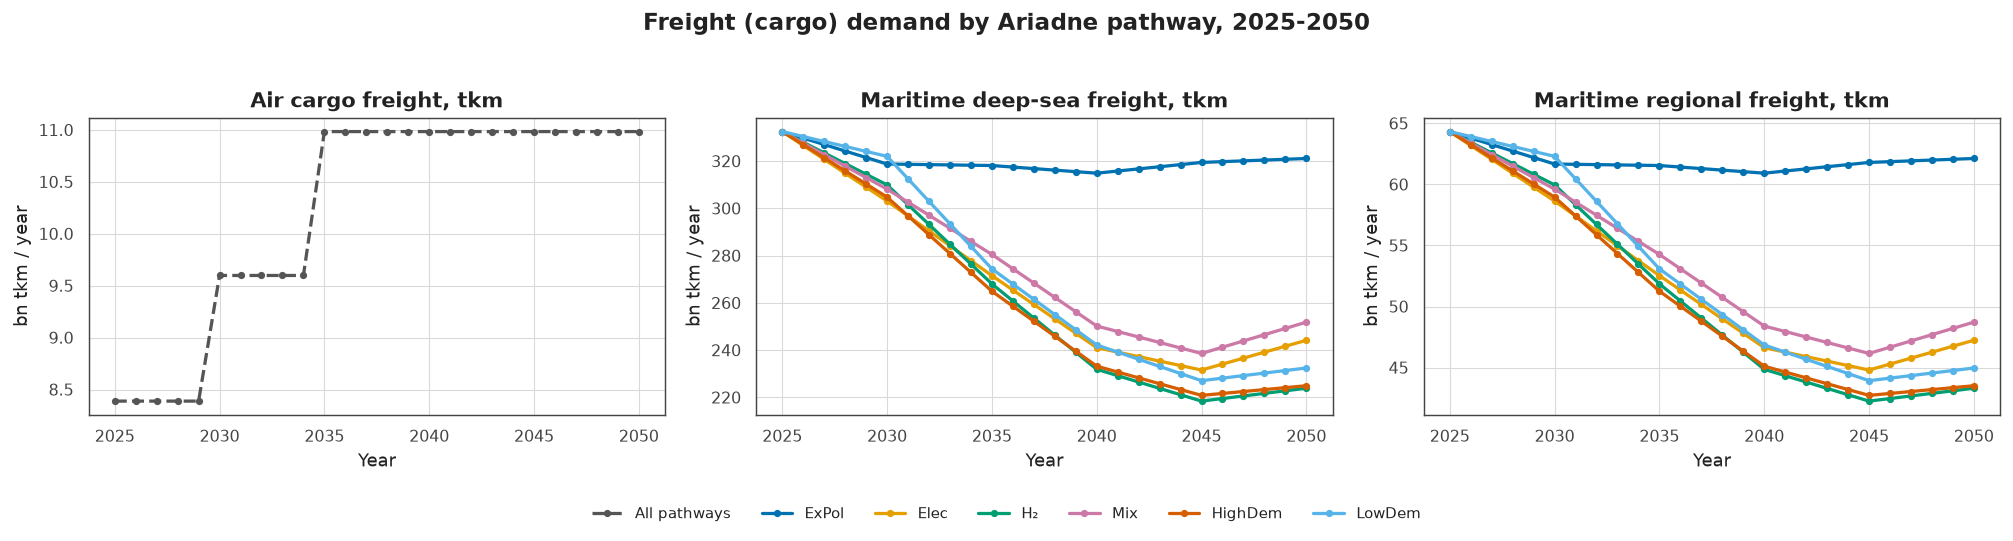

In [20]:
def plot_cargo_demand(rows, panels, ncols=3):
    order = PATHWAY_ORDER + (["common"] if any(r["pathway"]=="common" for r in rows) else [])
    colors=dict(COLORS); colors["common"]="#555555"
    labels=dict(PATHWAY_LABEL); labels["common"]="All pathways"
    fig, axes = plt.subplots(1, ncols, figsize=(5.2*ncols, 3.8), squeeze=False)
    axes=axes.ravel()
    for ax, panel in zip(axes, panels):
        for pw in order:
            pts=sorted([r for r in rows if r["panel"]==panel and r["pathway"]==pw], key=lambda r:r["year"])
            if not pts: continue
            ax.plot([p["year"] for p in pts],[p["v"] for p in pts], marker="o", ms=3,
                    lw=1.8, color=colors[pw], label=labels[pw],
                    linestyle="--" if pw=="common" else "-")
        ax.set_title(panel); ax.set_xlabel("Year"); ax.set_ylabel("bn tkm / year")
    seen={}
    for ax in axes[:len(panels)]:
        for h,l in zip(*ax.get_legend_handles_labels()): seen.setdefault(l,h)
    fig.legend(seen.values(), seen.keys(), ncol=min(7,len(seen)), loc="lower center",
               frameon=False, bbox_to_anchor=(0.5,-0.03))
    fig.suptitle("Freight (cargo) demand by Ariadne pathway, 2025-2050",
                 fontsize=13, fontweight="bold", y=1.03)
    fig.tight_layout(rect=(0,0.06,1,1))
    fig.savefig("scenario_cargo_demand_projections.png", bbox_inches="tight", dpi=150)
    fig.savefig("scenario_cargo_demand_projections.pdf", bbox_inches="tight")
    plt.show()

cargo_panels=["Air cargo freight, tkm","Maritime deep-sea freight, tkm","Maritime regional freight, tkm"]
plot_cargo_demand(cargo_demand, cargo_panels)


---

# Results §4.1 · Technology uptake across behavioural cases

**What this section shows.** For each transport sector we report *when* operators move away from fossil fuels and *which* alternative technologies they adopt, and we compare the six risk-neutral belief cases (RN-ExPol, RN-Elec, RN-H₂, RN-Mix, RN-HighDem, RN-LowDem) with the two risk-averse cases (Worst-case mean, Worst-case ES). All figures are read directly from NATM's executed outputs under `data/output/` (24 case folders); nothing is re-simulated.

**Denominator.** Uptake is reported as **fleet share by asset count** — the number of aircraft (aviation) or vessels (maritime) operating a given technology in a given year, divided by the total fleet that year. The headline "alternative share" line uses NATM's own `*_alternative_share` field, which equals one minus the fossil share (fossil = kerosene for aviation, marine diesel for maritime); the stacked-bar mix is computed from the per-technology `aircraft_count` / `vessel_count`.

**Reading note.** The carbon-price schedule is *identical across all six pathways and both risk-averse cases* within each sector (verified separately: aviation 35→105→180 €/tCO₂, maritime 28→78→152 €/tCO₂, rising to 2035 then flat). Divergence between cases therefore comes from the realised fuel/electricity prices each case experiences and, for the two worst-case cases, the robust decision rule — **not** from carbon pricing.


In [21]:
# ---- §4.1 loader: read fleet composition, alternative share, and investments ----
import os, re
import pandas as pd
from pathlib import Path

_PROJECT_ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == "analysis" else Path.cwd()
RESULTS_ROOT = _PROJECT_ROOT / "data" / "output"

# 8 behavioural cases (functional folder id -> paper label), in presentation order.
CASES = [
    ("aktuellepolitiken-risk-neutral", "RN–ExPol"),
    ("fokusstrom-risk-neutral",        "RN–Elec"),
    ("fokush2-risk-neutral",           "RN–H₂"),
    ("technologiemix-risk-neutral",    "RN–Mix"),
    ("hohenachfrage-risk-neutral",     "RN–HighDem"),
    ("nachfrageniedrig-risk-neutral",  "RN–LowDem"),
    ("worstcasemean-risk-averse",      "Worst-case mean"),
    ("worstcasetailrisk-risk-averse",  "Worst-case ES"),
]
CASE_ORDER = [lab for _, lab in CASES]

# Case colours: the six risk-neutral cases reuse their pathway colour; the two
# risk-averse cases are greys so they read as a different family.
CASE_COLOR = {
    "RN–ExPol": COLORS["aktuellepolitiken"], "RN–Elec": COLORS["fokusstrom"],
    "RN–H₂": COLORS["fokusH2"],          "RN–Mix": COLORS["technologiemix"],
    "RN–HighDem": COLORS["hohenachfrage"],    "RN–LowDem": COLORS["niedrigenachfrage"],
    "Worst-case mean": "#000000",                  "Worst-case ES": "#4D4D4D",
}

SECTORS = {
    "Aviation passenger": ("baseline-passenger-transition", "aviation", "aircraft_count"),
    "Aviation cargo":     ("baseline-cargo-transition",     "aviation", "aircraft_count"),
    "Maritime cargo":     ("baseline-maritime-cargo-transition", "maritime", "vessel_count"),
}
FOSSIL = {"aviation": "kerosene", "maritime": "marine_diesel"}

def _family(t):
    """Collapse a technology name to its fuel family (drop the segment suffix)."""
    return re.sub(r"_(long|medium|short|deepsea|regional)$", "", str(t))

# --- alternative share over time (model's own definition) ---
share_rows, mix_rows, cohort_rows = [], [], []
for folder, lab in CASES:
    for sector, (prefix, sp, stock) in SECTORS.items():
        base = RESULTS_ROOT / f"{prefix}-{folder}"
        summ = pd.read_csv(base / "model_summary.csv")
        for _, r in summ.iterrows():
            share_rows.append({"sector": sector, "case": lab, "year": int(r["year"]),
                               "alt_share": 100.0 * r[f"{sp}_alternative_share"]})
        tech = pd.read_csv(base / f"{sp}_technology.csv")
        tech["family"] = tech["current_technology"].map(_family)
        for yr in (2040, 2050):
            sub = tech[tech["year"] == yr]
            tot = sub[stock].sum()
            for famname, cnt in sub.groupby("family")[stock].sum().items():
                mix_rows.append({"sector": sector, "case": lab, "year": yr,
                                 "family": famname, "share": 100.0 * cnt / tot})
        # Early technology choice: of all aircraft/vessels purchased by 2030,
        # how many are alternative vs fossil (same renewal schedule, different fuel choice).
        inv = pd.read_csv(base / f"{sp}_investments.csv")
        inv["family"] = inv["current_technology"].map(_family)
        early = inv[inv["year"] <= 2030]
        n_tot = early[stock].sum()
        n_foss = early.loc[early["family"] == FOSSIL[sp], stock].sum()
        cohort_rows.append({"sector": sector, "case": lab,
                            "alt": int(n_tot - n_foss), "fossil": int(n_foss)})

alt_share = pd.DataFrame(share_rows)
mix = pd.DataFrame(mix_rows)
cohort = pd.DataFrame(cohort_rows)
print("Loaded", alt_share["case"].nunique(), "cases x", alt_share["sector"].nunique(), "sectors;",
      f"{len(alt_share)} share rows, {len(mix)} mix rows.")
alt_share.head()


Loaded 8 cases x 3 sectors; 624 share rows, 258 mix rows.


,sector,case,year,alt_share
0,Aviation passenger,RN–ExPol,2025,0.000000
1,Aviation passenger,RN–ExPol,2026,20.246479
2,Aviation passenger,RN–ExPol,2027,23.239437
3,Aviation passenger,RN–ExPol,2028,24.295775
4,Aviation passenger,RN–ExPol,2029,24.295775


### Figure 4.1a — Alternative-technology fleet share over time

The headline transition curve for each sector, one line per behavioural case.

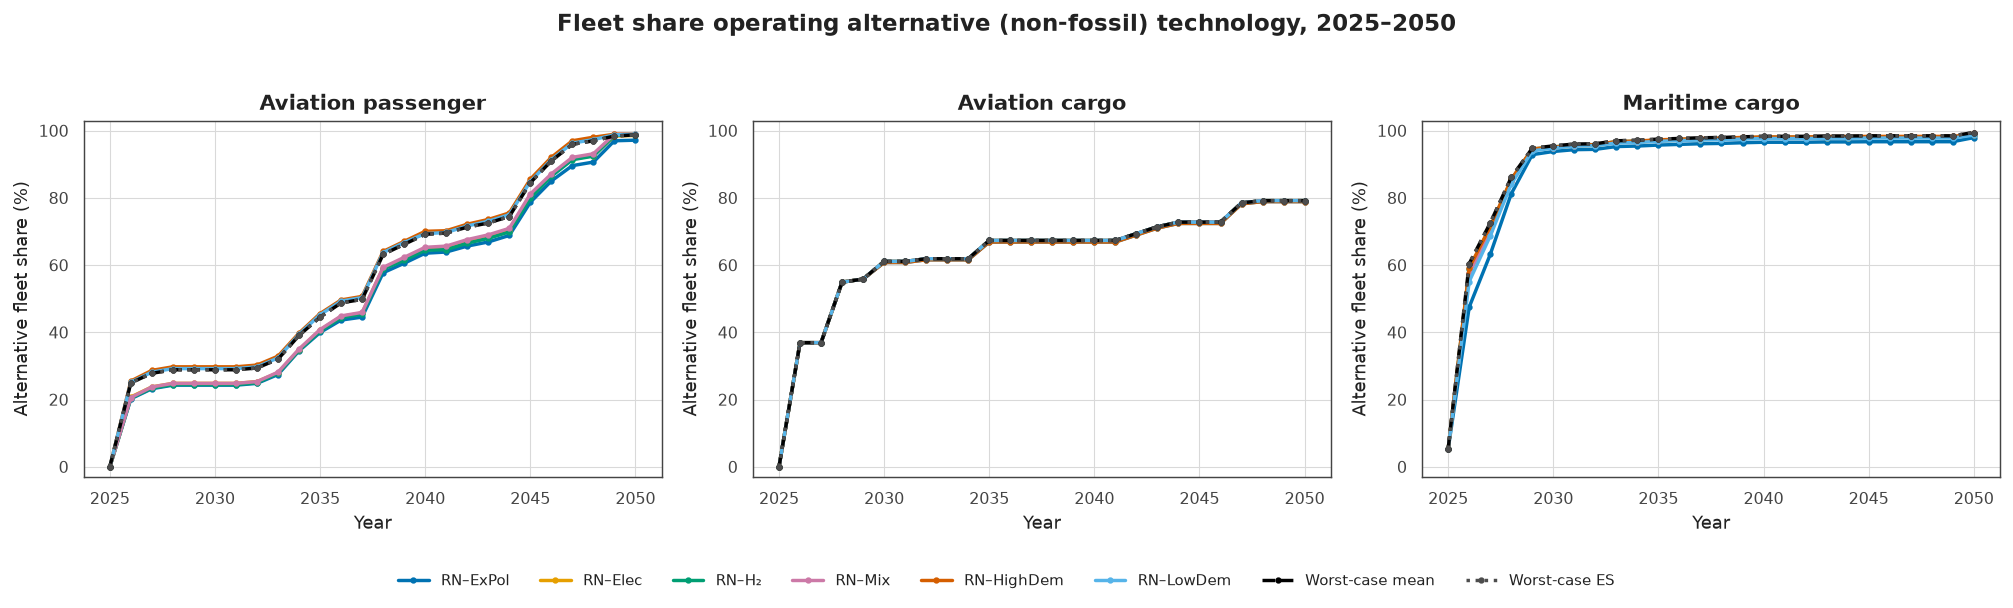

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15.6, 4.2), squeeze=False)
axes = axes.ravel()
for ax, sector in zip(axes, SECTORS):
    sub = alt_share[alt_share["sector"] == sector]
    for lab in CASE_ORDER:
        d = sub[sub["case"] == lab].sort_values("year")
        ax.plot(d["year"], d["alt_share"], lw=1.9, color=CASE_COLOR[lab], label=lab,
                marker="o", ms=2.5,
                linestyle={"Worst-case mean": "--", "Worst-case ES": ":"}.get(lab, "-"))
    ax.set_title(sector); ax.set_xlabel("Year")
    ax.set_ylabel("Alternative fleet share (%)"); ax.set_ylim(-3, 103)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=8, loc="lower center", frameon=False,
           bbox_to_anchor=(0.5, -0.05), fontsize=8.5)
fig.suptitle("Fleet share operating alternative (non-fossil) technology, 2025–2050",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("results_41a_alternative_share.png", bbox_inches="tight", dpi=150)
fig.savefig("results_41a_alternative_share.pdf", bbox_inches="tight")
plt.show()


**What the curves show.**

- **Maritime cargo transitions first and fastest.** Alternative share jumps from ~5 % (2025) to **94–96 % by 2030** in every case, then edges to 98–99 % by 2050. This is a *greenfield* transition: the German-flagged fleet scales from 131 vessels (2025) to ~1,940–2,060 by 2030 to meet freight demand, and essentially every new vessel is alternative (≥80 % of 2026 newbuilds, 100 % from 2027). Case spread is small (≤1.5 pp in any year).
- **Aviation cargo plateaus, then resumes.** All cases reach ~61 % by 2030 and ~67 % by 2035, hold there, then climb to **79 %** by 2050. The mid-horizon plateau reflects a fleet that has already converted its replaceable cohort and waits for the next renewal window. Spread across cases is ≤0.5 pp.
- **Aviation passenger is the gradual, most case-dependent transition.** Share rises steadily 24–30 % (2030) → 40–46 % (2035) → 64–70 % (2040) → **97–99 %** (2050). Here the cases separate by **5–6 pp through 2030–2040**: RN-HighDem, RN-LowDem and both worst-case cases run ahead of the four policy/technology-belief cases (RN-ExPol, RN-Elec, RN-H₂, RN-Mix). This is the sector where behavioural assumptions matter most, so it anchors the divergence analysis below.


### Figure 4.1b — 2050 fuel-family composition by case

*Which* alternative wins, by sector. Each bar is one case; segments are fleet share by fuel family in 2050.

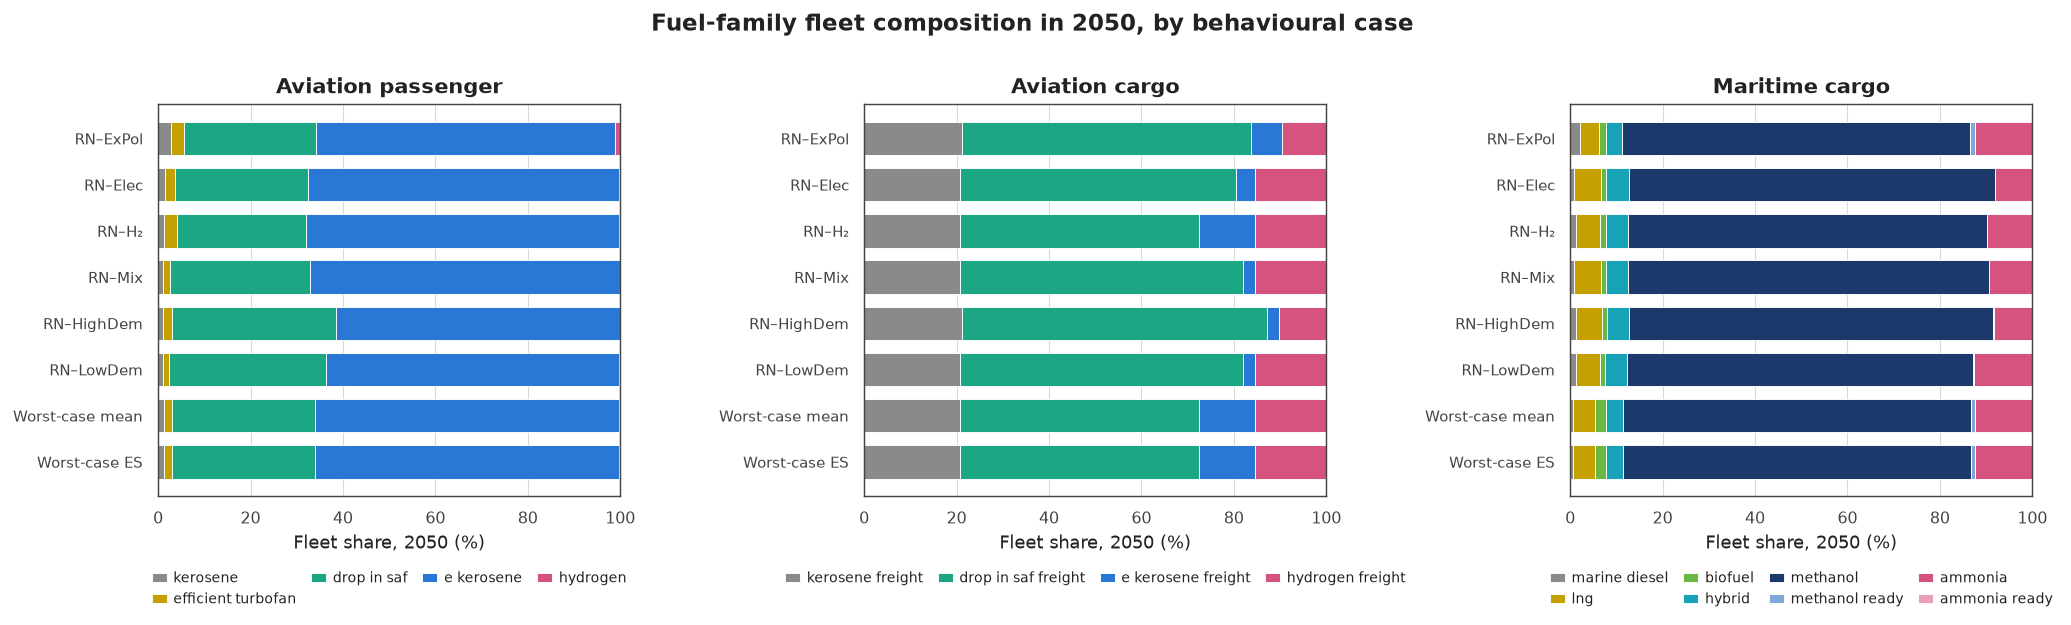

In [23]:
def _mix_panel(ax, sector, year, fams, palette):
    sub = mix[(mix["sector"] == sector) & (mix["year"] == year)]
    piv = (sub.pivot_table(index="case", columns="family", values="share", aggfunc="sum")
              .reindex(CASE_ORDER).reindex(columns=fams).fillna(0.0))
    left = pd.Series(0.0, index=piv.index)
    y = range(len(piv))
    for fam in fams:
        ax.barh(list(y), piv[fam].values, left=left.values, color=palette[fam],
                label=fam.replace("_", " "), height=0.72, edgecolor="white", linewidth=0.5)
        left += piv[fam]
    ax.set_yticks(list(y)); ax.set_yticklabels(piv.index, fontsize=8.5)
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("Fleet share, 2050 (%)")
    ax.set_title(sector); ax.grid(axis="y", visible=False)
    ax.legend(fontsize=7.5, ncol=min(4, len(fams)), loc="upper center",
              bbox_to_anchor=(0.5, -0.16), frameon=False, handlelength=1.1,
              columnspacing=1.1, handletextpad=0.5)

AV_FAMS = ["kerosene", "efficient_turbofan", "drop_in_saf", "e_kerosene", "hydrogen"]
AVC_FAMS = ["kerosene_freight", "drop_in_saf_freight", "e_kerosene_freight", "hydrogen_freight"]
MA_FAMS = ["marine_diesel", "lng", "biofuel", "hybrid", "methanol", "methanol_ready", "ammonia", "ammonia_ready"]
AV_PAL = {"kerosene": "#8A8A8A", "efficient_turbofan": "#C4A000", "drop_in_saf": "#1BA784",
          "e_kerosene": "#2A78D6", "hydrogen": "#D6537F"}
AVC_PAL = {"kerosene_freight": "#8A8A8A", "drop_in_saf_freight": "#1BA784",
           "e_kerosene_freight": "#2A78D6", "hydrogen_freight": "#D6537F"}
MA_PAL = {"marine_diesel": "#8A8A8A", "lng": "#C4A000", "biofuel": "#6BB745", "hybrid": "#17A2B8",
          "methanol": "#1B3A6B", "methanol_ready": "#7FA8D6", "ammonia": "#D6537F", "ammonia_ready": "#E8A0B8"}

fig, axes = plt.subplots(1, 3, figsize=(16, 5.0))
_mix_panel(axes[0], "Aviation passenger", 2050, AV_FAMS, AV_PAL)
_mix_panel(axes[1], "Aviation cargo", 2050, AVC_FAMS, AVC_PAL)
_mix_panel(axes[2], "Maritime cargo", 2050, MA_FAMS, MA_PAL)
fig.suptitle("Fuel-family fleet composition in 2050, by behavioural case",
             fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig("results_41b_fuel_mix_2050.png", bbox_inches="tight", dpi=150)
fig.savefig("results_41b_fuel_mix_2050.pdf", bbox_inches="tight")
plt.show()


**What the composition shows.** By 2050 every case is near-fully alternative, but the *blend* differs by the price world each case experiences:

- **Aviation passenger** settles on **e-kerosene (61–68 %) plus drop-in SAF (28–36 %)**, with only residual kerosene/hydrogen. RN-HighDem and RN-LowDem carry the most drop-in SAF (34–36 %) and the least e-kerosene; the four policy/technology-belief cases lean further into e-kerosene.
- **Aviation cargo** is **drop-in-SAF-dominated (52–66 %)**. The split is in the remainder: RN-H₂ and both worst-case cases take noticeably more **e-kerosene (12 %)** and less SAF (52 %), while RN-HighDem maximises SAF (66 %). Hydrogen holds a stable ~10–15 % freight niche (medium-haul).
- **Maritime cargo** is **methanol-led (75–79 %)** with **ammonia second (8–13 %)**. RN-ExPol, RN-LowDem and the worst-case cases keep the most ammonia (12–13 %); RN-Elec pushes furthest into methanol (79 %). LNG, hybrid and biofuel remain small (<6 % each).


### Figure 4.1c — Where the cases diverge: early technology choice (passenger aviation)

The fleet-*renewal schedule* is identical across cases — every passenger case buys the same 151 aircraft in 2026, 18 in 2027, 6 in 2028 (fleet 474→568). What differs is **which fuel** each renewal is bought as. The bars split the ≤2030 purchase cohort into alternative vs fossil-kerosene aircraft.

findfont: Failed to find font weight semibold, now using 700.


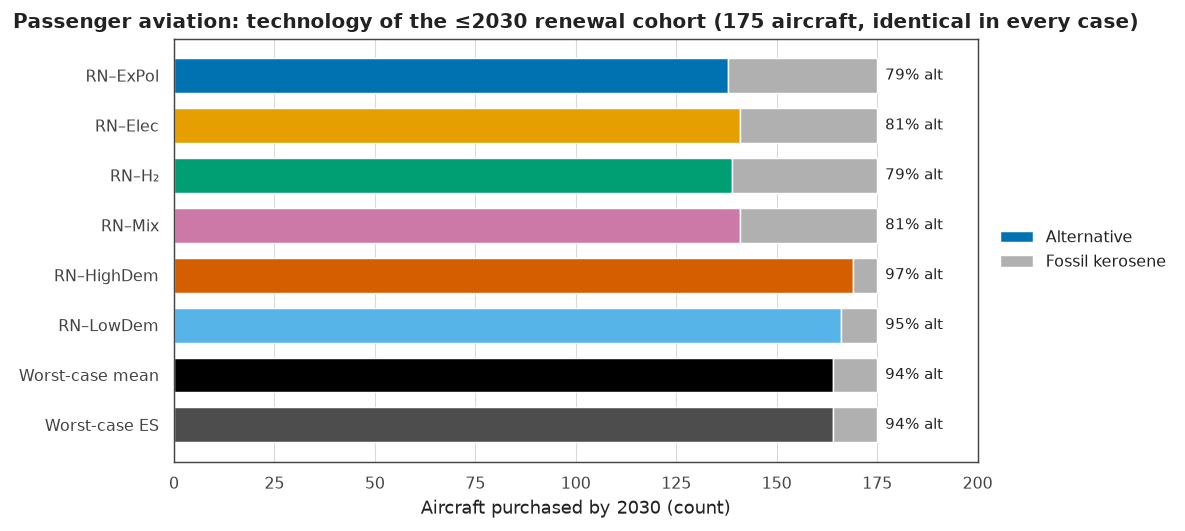

In [24]:
sub = cohort[cohort["sector"] == "Aviation passenger"].set_index("case").reindex(CASE_ORDER)
fig, ax = plt.subplots(figsize=(9.2, 4.2))
y = range(len(sub))
ax.barh(list(y), sub["alt"].values, color=[CASE_COLOR[c] for c in sub.index],
        height=0.7, label="Alternative", edgecolor="white")
ax.barh(list(y), sub["fossil"].values, left=sub["alt"].values, color="#B0B0B0",
        height=0.7, label="Fossil kerosene", edgecolor="white")
for i, (a, f) in enumerate(zip(sub["alt"], sub["fossil"])):
    ax.text(a + f + 2, i, f"{100*a/(a+f):.0f}% alt", va="center", fontsize=8.5)
ax.set_yticks(list(y)); ax.set_yticklabels(sub.index); ax.invert_yaxis()
ax.set_xlabel("Aircraft purchased by 2030 (count)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 200); ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9, frameon=False)
ax.set_title("Passenger aviation: technology of the ≤2030 renewal cohort (175 aircraft, identical in every case)",
             fontsize=11)
fig.tight_layout()
fig.savefig("results_41c_early_choice.png", bbox_inches="tight", dpi=150)
fig.savefig("results_41c_early_choice.pdf", bbox_inches="tight")
plt.show()


**Interpretation — the divergence is a fuel-choice margin, not a fleet-turnover difference.**

Of the 175 passenger aircraft renewed by 2030, the share bought as alternative rather than fossil kerosene is:

| Case group | Alt. of ≤2030 cohort | Fossil kept |
|---|---|---|
| RN-HighDem / RN-LowDem / Worst-case mean / ES | **164–169 (94–97 %)** | 6–11 |
| RN-ExPol / RN-Elec / RN-H₂ / RN-Mix | **138–141 (79–81 %)** | 34–37 |

Because the renewal *volume and timing* are identical across cases, the 5–6 pp gap in Figure 4.1a is produced entirely at the **point of technology choice**: in the HighDem/LowDem price worlds and under the robust decision rule, the alternative (overwhelmingly drop-in SAF — 96 % of early alternative buys in **every** case) clears its NPV hurdle against fossil kerosene for almost the whole cohort, whereas the four policy/technology-belief cases still retain ~35 fossil replacements whose kerosene economics remain competitive in their realised price world. Early-cohort capital outlay rises accordingly, from ~€9.7 bn (RN-ExPol) to ~€11.0 bn (RN-HighDem), consistent with buying ~30 more of the slightly dearer low-carbon aircraft up front.

**What the outputs do and do not support.**

- *Supported directly:* the fleet-renewal schedule, the alternative-vs-fossil split of each cohort, the 2050 fuel blends, and the near-identical carbon-price path — all read from the per-case output files.
- *Interpretation (consistent with, but not proven by, these outputs):* attributing the early-choice gap specifically to realised fuel/electricity-price differences and to the robust rule's hedging. A full attribution would read the per-candidate `ambiguity_decision_scores.csv` NPV rankings case by case; here we report the choices and their price context, not a decomposed NPV.
- *Scope:* uptake is by **asset count**. Because segments (short/medium/long, regional/deepsea) differ in size and utilisation, an **activity-weighted** denominator (seat-km or tonne-km) could shift the maritime and long-haul figures; this is a natural robustness check to add.
